> *Données : © Open Food Facts contributors — ODbL.*

# Classifieur d'images

In [94]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

from nutriscope.classification import RANDOM_SEED

print(f"TensorFlow : {tf.__version__}")
print(f"GPU disponible : {tf.config.list_physical_devices('GPU')}")

TensorFlow : 2.22.0-rc0
GPU disponible : []


In [ ]:
%python "../src/images_bucket/telecharger_images.py" --rayons biscuits sodas jus fromages chocolats eaux --dest "../data/images"

## Analyse des images

`3061990143587.jpg`, `4823077621642.jpg` dans les images `biscuit` ne représente pas une boîte de biscuits mais un code-barre. + image d'informations nutritionnelles

In [ ]:
image_size = (96, 96)
directory = Path("../data/images")
dataset_raw = tf.keras.preprocessing.image_dataset_from_directory(directory, batch_size=None, image_size=image_size, pad_to_aspect_ratio=True)

Found 3000 files belonging to 6 classes.


In [ ]:
class_names = dataset_raw.class_names
num_classes = len(class_names)

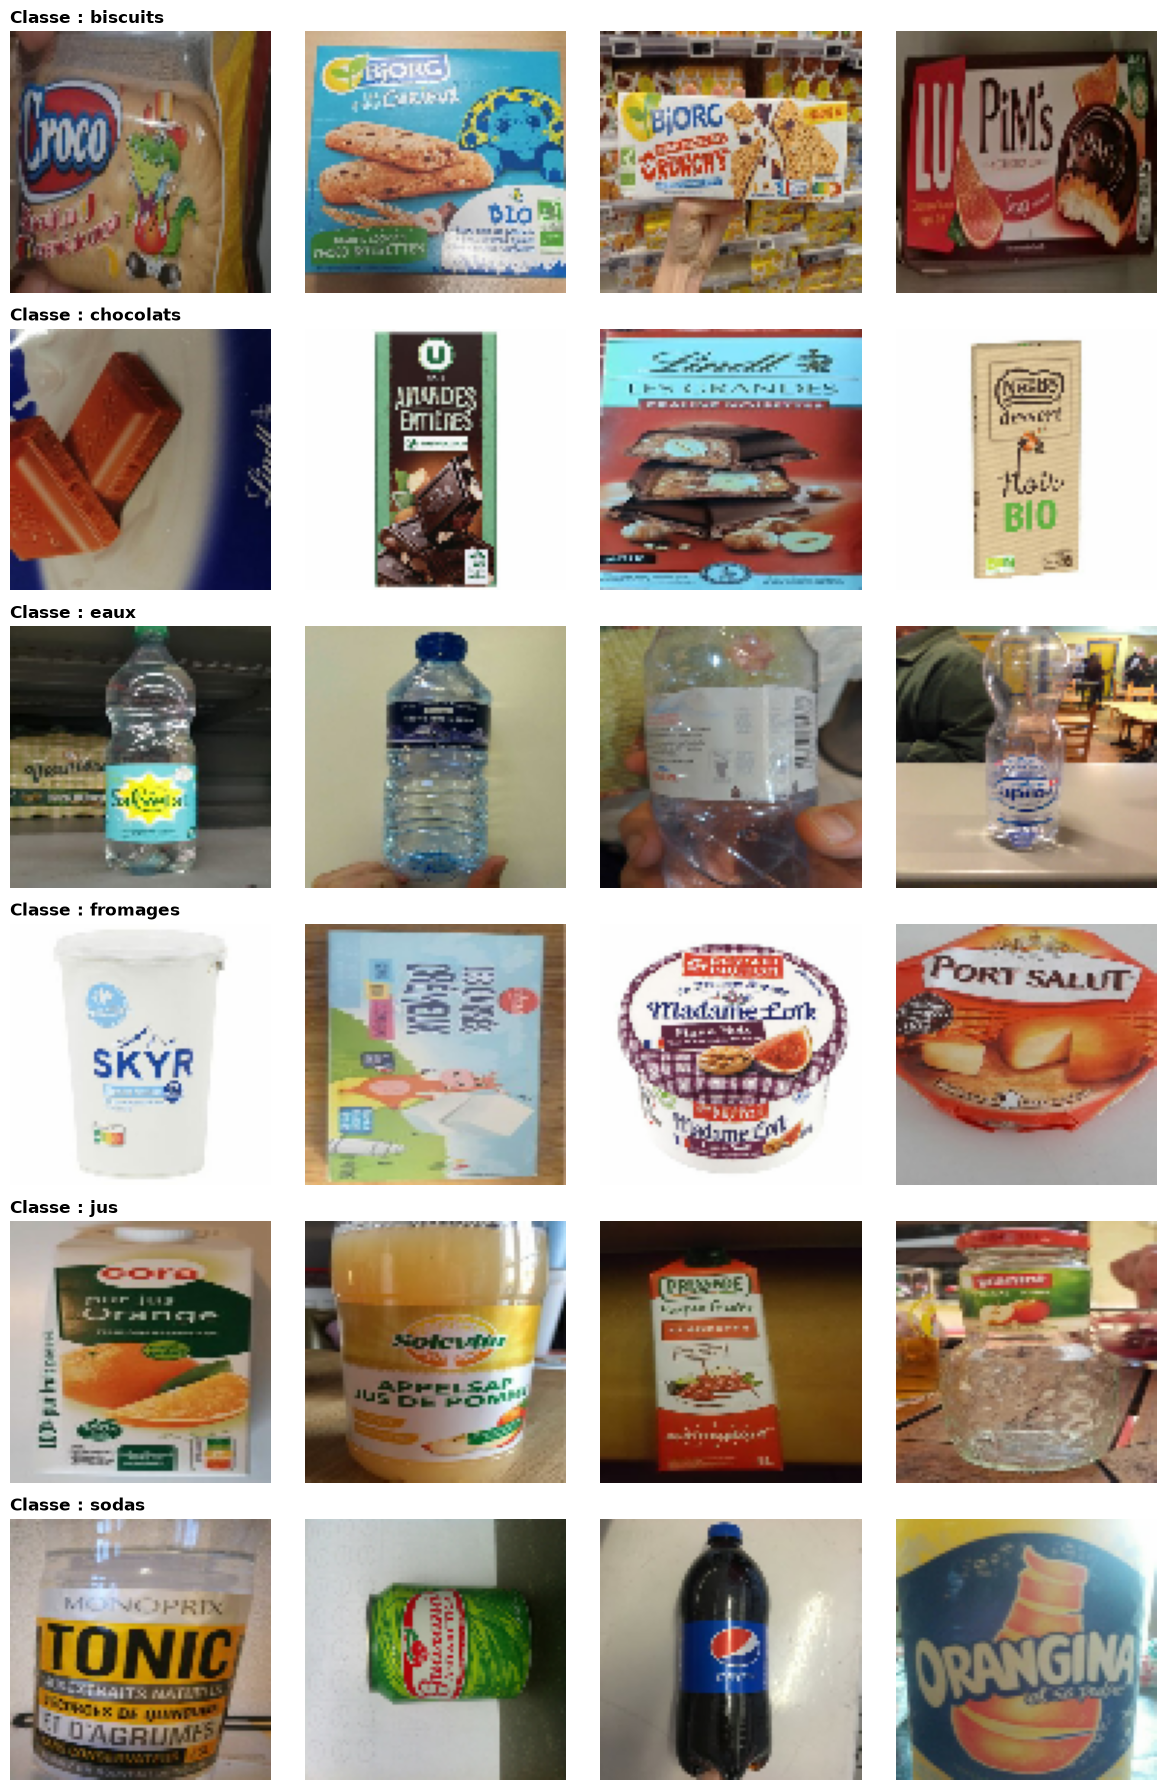

In [97]:
classes = {name: [] for name in class_names}
nb_img_columns = 4

for img, label in dataset_raw.shuffle(
  buffer_size=dataset_raw.cardinality(), seed=RANDOM_SEED, reshuffle_each_iteration=False
):
  img_np = img.numpy().astype("uint8")
  label_idx = label.numpy()
  c_name = class_names[label_idx]

  # Si cette classe n'a pas encore 4 images, on l'ajoute
  if len(classes[c_name]) < nb_img_columns:
    classes[c_name].append(img_np)

  # Condition d'arrêt pour éviter de parcourir tout le dataset inutilement
  if all(len(imgs) == nb_img_columns for imgs in classes.values()):
    break

fig, axes = plt.subplots(num_classes, nb_img_columns, figsize=(12, 3 * num_classes))

if num_classes == 1:
  axes = [axes]

for i, class_name in enumerate(class_names):
  imgs = classes[class_name]
  k = len(imgs)

  for j in range(nb_img_columns):
    ax = axes[i][j] if num_classes > 1 else axes[j]
    ax.axis("off")

    if j < k:
      ax.imshow(imgs[j])
      if j == 0:
        ax.set_title(
            f"Classe : {class_name}", fontsize=12, fontweight="bold", loc="left"
        )
    else:
      ax.text(
          0.5,
          0.5,
          "Pas assez d'images",
          ha="center",
          va="center",
          transform=ax.transAxes,
          color="gray",
      )

plt.tight_layout()
plt.show()

In [ ]:
dataset = dataset_raw.map(lambda x, y: (x / 255.0, y))

# Extraire toutes les images et labels en mémoire
images, labels = [], []
for img, label in dataset:
    images.append(img.numpy())
    labels.append(label.numpy())

X = np.stack(images).astype(np.float32)
y = np.array(labels)

# Split stratifié
X_train_val, X_test, y_train_val, y_test_raw = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15, stratify=y_train_val, random_state=RANDOM_SEED
)


In [99]:
# One-hot encoding des labels
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_val_cat   = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_cat  = tf.keras.utils.to_categorical(y_test_raw, num_classes)

print(f"X_train : {X_train.shape}  →  y_train : {y_train_cat.shape}")
print(f"X_val   : {X_val.shape}  →  y_val   : {y_val_cat.shape}")
print(f"X_test  : {X_test.shape}  →  y_test  : {y_test_cat.shape}")

X_train : (1200, 90, 90, 3)  →  y_train : (1200, 6)
X_val   : (1200, 90, 90, 3)  →  y_val   : (1200, 6)
X_test  : (600, 90, 90, 3)  →  y_test  : (600, 6)


In [100]:
def build_cnn(num_classes=10):
    model = models.Sequential([
        layers.Input(shape=(90, 90, 3)),

        # --- Bloc 1 : extraction de features simples ---
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 28×28 → 14×14
        layers.Dropout(0.25),

        # --- Bloc 2 : extraction de features complexes ---
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 14×14 → 7×7
        layers.Dropout(0.25),

        # --- Tête de classification ---
        layers.Flatten(),              # 7×7×64 = 3136 neurones
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='CNN')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn(num_classes)
model.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 90, 90, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 90, 90, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 45, 45, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,031,398 (15.38 MB)

 Trainable params: 4,031,398 (15.38 MB)

 Non-trainable params: 0 (0.00 B)

In [101]:
checkpoint_dir = Path("../data/checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)
model_ckpt = callbacks.ModelCheckpoint(
    filepath=checkpoint_dir / "cnn_best.keras",
    monitor='val_accuracy', save_best_only=True, verbose=0
)

history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=20,
    batch_size=128,
    verbose=1,
    callbacks=[early_stop, model_ckpt]
)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 398ms/step - accuracy: 0.1433 - loss: 2.1404 - val_accuracy: 0.1908 - val_loss: 1.7909
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 355ms/step - accuracy: 0.1817 - loss: 1.7917 - val_accuracy: 0.1667 - val_loss: 1.7869
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 349ms/step - accuracy: 0.1650 - loss: 1.7870 - val_accuracy: 0.1725 - val_loss: 1.7831
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 350ms/step - accuracy: 0.1767 - loss: 1.7793 - val_accuracy: 0.1900 - val_loss: 1.7508
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - accuracy: 0.2200 - loss: 1.7318 - val_accuracy: 0.3025 - val_loss: 1.6910
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 373ms/step - accuracy: 0.3000 - loss: 1.6823 - val_accuracy: 0.3867 - val_loss: 1.6018
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 369ms/step - accuracy: 0.3633 - loss: 1.5814 - val_accuracy: 0.4233 - val_loss: 1.5383
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 377ms/step - accuracy: 0.3900 - loss: 1.5369 - val_accuracy: 0.

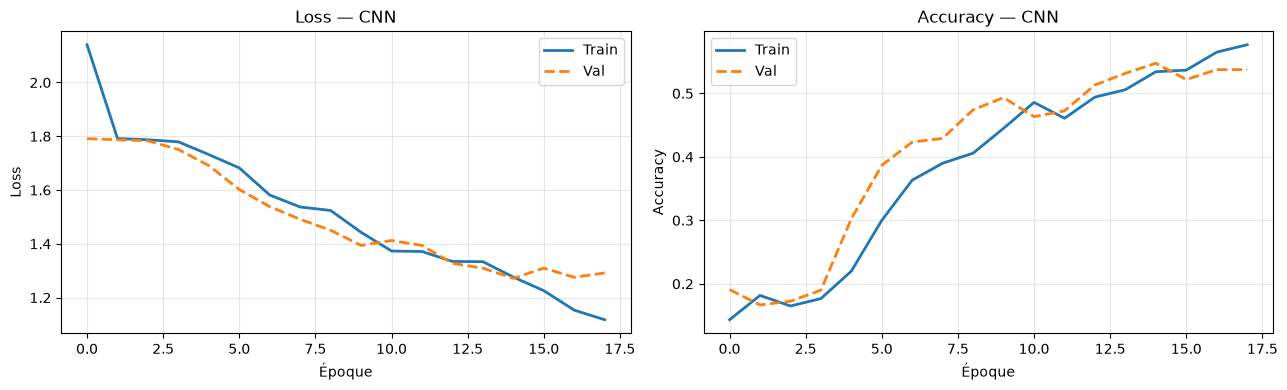

In [102]:
def plot_loss_acc(history, title=''):
    """Trace les courbes de loss et d'accuracy."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    ax1.plot(history.history['loss'],     label='Train', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val',   linewidth=2, linestyle='--')
    ax1.set_title(f'Loss {title}'); ax1.set_xlabel('Époque'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(history.history['accuracy'],     label='Train', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val',   linewidth=2, linestyle='--')
    ax2.set_title(f'Accuracy {title}'); ax2.set_xlabel('Époque'); ax2.set_ylabel('Accuracy')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_loss_acc(history, '— CNN')

In [103]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print("\nClassification Report :")
print(classification_report(y_test_raw, y_pred, target_names=class_names))

Test Loss     : 1.2424
Test Accuracy : 0.5467  (54.67%)

Classification Report :
              precision    recall  f1-score   support

    biscuits       0.55      0.54      0.55       100
   chocolats       0.63      0.62      0.62       100
        eaux       0.60      0.58      0.59       100
    fromages       0.56      0.61      0.58       100
         jus       0.50      0.61      0.55       100
       sodas       0.43      0.32      0.37       100

    accuracy                           0.55       600
   macro avg       0.54      0.55      0.54       600
weighted avg       0.54      0.55      0.54       600



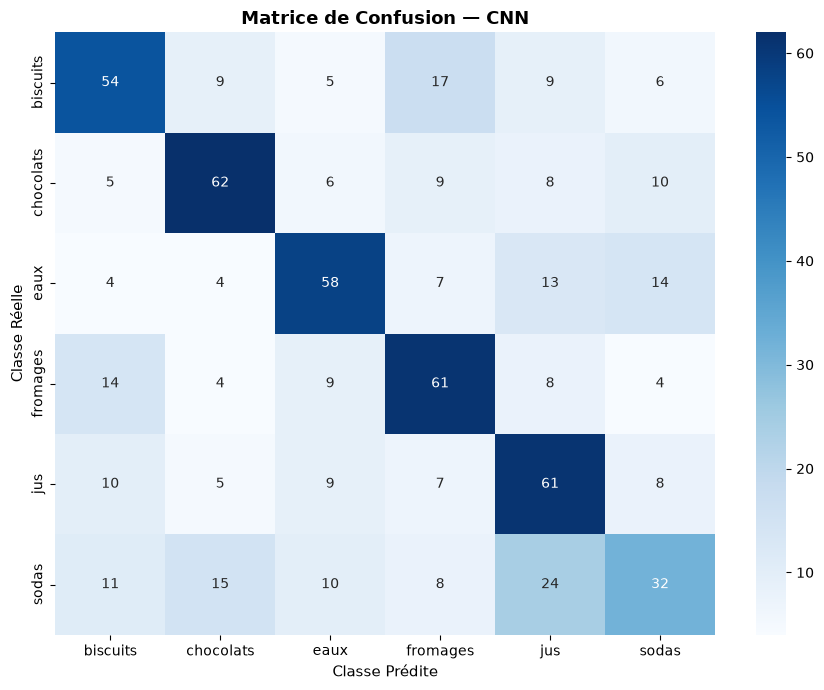

In [104]:
cm = confusion_matrix(y_test_raw, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de Confusion — CNN", fontsize=13, fontweight='bold')
plt.xlabel("Classe Prédite", fontsize=11)
plt.ylabel("Classe Réelle", fontsize=11)
plt.tight_layout()
plt.show()

## MobilNet

In [116]:
def build_feature_extraction_model(num_classes=10):
    # Chargement de MobileNetV2 sans la tête de classification
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(90, 90, 3),  # taille native pour cette variante
        include_top=False,        # pas de Dense(1000) ImageNet
        weights='imagenet'        # poids pré-entraînés
    )
    # Geler TOUTES les couches du modèle de base
    base_model.trainable = False

    # Construction du modèle complet
    inp = tf.keras.Input(shape=(90, 90, 3), name='input_image')
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inp)

    # Extraction de features (poids gelés)
    x = base_model(inp, training=False)          # training=False : BatchNorm en mode inférence

    # Tête de classification personnalisée
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.3, name='dropout')(x)
    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = tf.keras.Model(inp, out, name='TransferModel_FeatureExtraction')
    return model, base_model

model_fe, base_model = build_feature_extraction_model(num_classes)

total_p      = model_fe.count_params()
trainable_p  = sum(tf.keras.backend.count_params(w) for w in model_fe.trainable_weights)
frozen_p     = total_p - trainable_p

print(f"Paramètres totaux MobileNetV2 + tête : {total_p:>10,}")
print(f"  → Entraînables (tête uniquement)   : {trainable_p:>10,}")
print(f"  → Gelés (base MobileNetV2)         : {frozen_p:>10,}")
print(f"  → Ratio entraîné / total           : {trainable_p/total_p*100:.1f}%")

C:\Users\Administrateur\AppData\Local\Temp\ipykernel_7200\1400505799.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Paramètres totaux MobileNetV2 + tête :  2,265,670
  → Entraînables (tête uniquement)   :      7,686
  → Gelés (base MobileNetV2)         :  2,257,984
  → Ratio entraîné / total           : 0.3%


In [117]:
model_fe.summary()

Model: "TransferModel_FeatureExtraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 90, 90, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [118]:
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_fe = callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)
ckpt_fe = callbacks.ModelCheckpoint(
    filepath=checkpoint_dir / "tl_fe_best.keras",
    monitor='val_accuracy', save_best_only=True, verbose=0
)

print("=" * 60)
print("Phase 1 : Feature Extraction")
print("Seule la tête de classification est entraînée.")
print("=" * 60)

history_fe = model_fe.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=64,
    verbose=0,
    callbacks=[early_stop_fe, ckpt_fe]
)

loss_fe, acc_fe = model_fe.evaluate(X_test, y_test_cat, verbose=0)
print(f"\n✓ Phase 1 terminée — Test Accuracy : {acc_fe:.4f} ({acc_fe*100:.2f}%)")

Phase 1 : Feature Extraction
Seule la tête de classification est entraînée.
Epoch 12: early stopping
Restoring model weights from the end of the best epoch: 9.

✓ Phase 1 terminée — Test Accuracy : 0.6567 (65.67%)


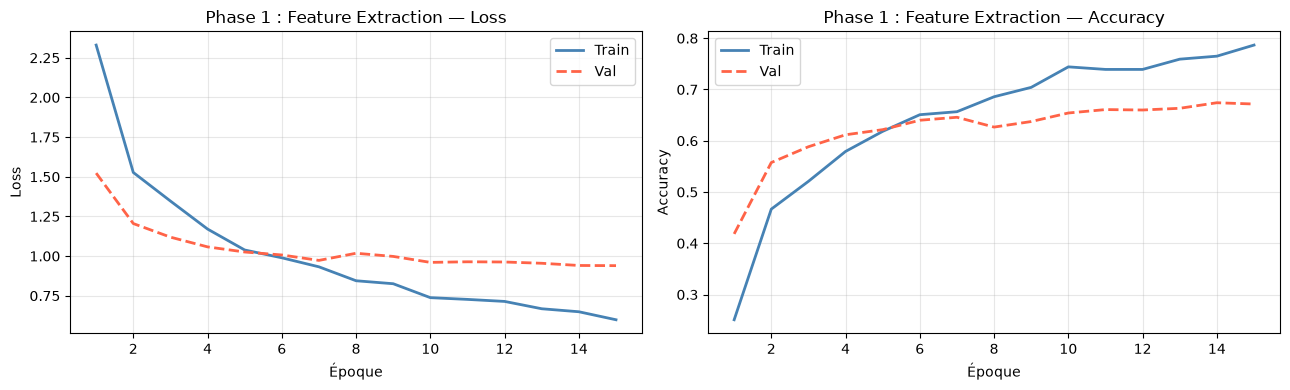

In [108]:
def plot_history(history, title, color_train='steelblue', color_val='tomato'):
    """Trace les courbes de loss et accuracy."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    epochs = range(1, len(history.history['loss']) + 1)

    ax1.plot(epochs, history.history['loss'],     color=color_train, label='Train', linewidth=2)
    ax1.plot(epochs, history.history['val_loss'], color=color_val, linestyle='--', label='Val', linewidth=2)
    ax1.set_title(f'{title} — Loss'); ax1.set_xlabel('Époque'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history.history['accuracy'],     color=color_train, label='Train', linewidth=2)
    ax2.plot(epochs, history.history['val_accuracy'], color=color_val, linestyle='--', label='Val', linewidth=2)
    ax2.set_title(f'{title} — Accuracy'); ax2.set_xlabel('Époque'); ax2.set_ylabel('Accuracy')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_fe, 'Phase 1 : Feature Extraction', 'steelblue', 'tomato')

## Fine-Tuning

In [109]:
# Charger le meilleur modèle de la phase FE
model_ft = tf.keras.models.load_model(checkpoint_dir / "tl_fe_best.keras")

# Retrouver le modèle de base (MobileNetV2)
base = next(l for l in model_ft.layers if 'mobilenet' in l.name.lower())
print(f"Modèle de base trouvé : {base.name}")
print(f"Nombre total de couches : {len(base.layers)}")

# Dégeler les 30 dernières couches
base.trainable = True
N_UNFREEZE = 30
for layer in base.layers[:-N_UNFREEZE]:
    layer.trainable = False

frozen    = sum(1 for l in base.layers if not l.trainable)
unfrozen  = sum(1 for l in base.layers if l.trainable)
trainable_p_ft = sum(tf.keras.backend.count_params(w) for w in model_ft.trainable_weights)

print(f"\nCouches gelées   : {frozen}")
print(f"Couches dégelées : {unfrozen} (dernières {N_UNFREEZE})")
print(f"Paramètres entraînables (FT) : {trainable_p_ft:,}")

Modèle de base trouvé : mobilenetv2_1.00_224
Nombre total de couches : 154

Couches gelées   : 124
Couches dégelées : 30 (dernières 30)
Paramètres entraînables (FT) : 1,534,086


In [110]:
# Recompiler avec un learning rate très faible
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # 100× plus faible qu'en FE
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_ft = callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)
ckpt_ft = callbacks.ModelCheckpoint(
    filepath=checkpoint_dir / "tl_ft_best.keras",
    monitor='val_accuracy', save_best_only=True, verbose=0
)

print("=" * 60)
print("Phase 2 : Fine-Tuning")
print(f"LR = 1e-5 (vs 1e-3 en FE) — 30 dernières couches dégelées")
print("=" * 60)

history_ft = model_ft.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=10,
    batch_size=64,
    verbose=1,
    callbacks=[early_stop_ft, ckpt_ft]
)

loss_ft, acc_ft = model_ft.evaluate(X_test, y_test_cat, verbose=0)
print(f"\n✓ Phase 2 terminée — Test Accuracy : {acc_ft:.4f} ({acc_ft*100:.2f}%)")

Phase 2 : Fine-Tuning
LR = 1e-5 (vs 1e-3 en FE) — 30 dernières couches dégelées
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 433ms/step - accuracy: 0.5017 - loss: 1.4125 - val_accuracy: 0.6725 - val_loss: 0.9420
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 394ms/step - accuracy: 0.5717 - loss: 1.2394 - val_accuracy: 0.6767 - val_loss: 0.9440
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 394ms/step - accuracy: 0.5750 - loss: 1.1565 - val_accuracy: 0.6800 - val_loss: 0.9462
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 379ms/step - accuracy: 0.6217 - loss: 1.0587 - val_accuracy: 0.6792 - val_loss: 0.9444
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

✓ Phase 2 terminée — Test Accuracy : 0.6750 (67.50%)


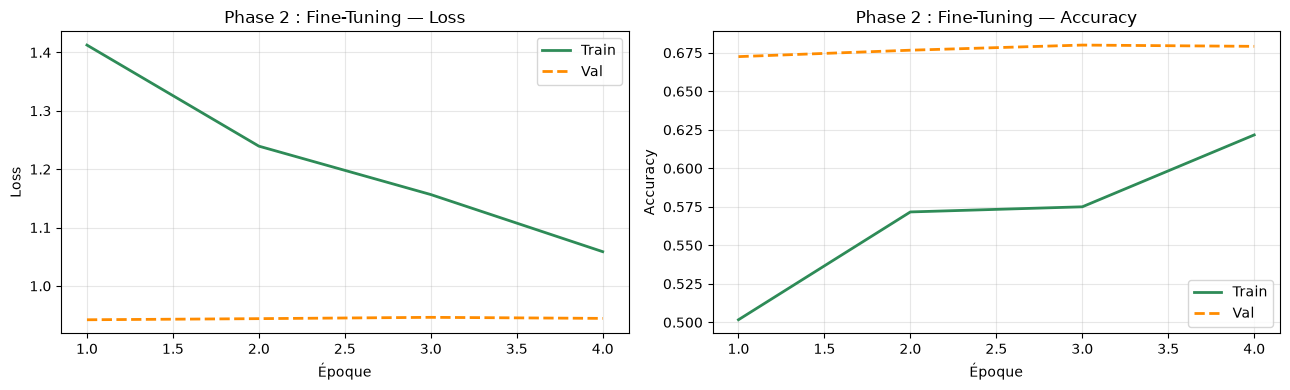

In [111]:
plot_history(history_ft, 'Phase 2 : Fine-Tuning', 'seagreen', 'darkorange')

## Comparaison résultats

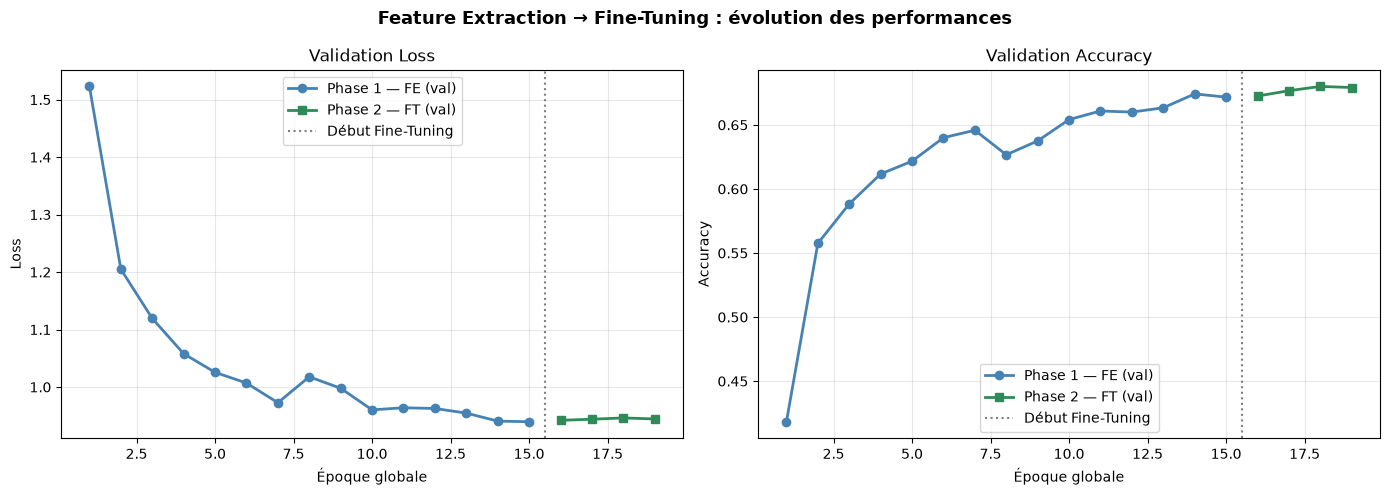

In [112]:
# Courbes combinées : FE + FT
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Épochs FE
e_fe = range(1, len(history_fe.history['val_accuracy'])+1)
e_ft = range(
    len(history_fe.history['val_accuracy'])+1,
    len(history_fe.history['val_accuracy'])+len(history_ft.history['val_accuracy'])+1
)

for ax, key, ylabel in [(ax1, 'val_loss', 'Loss'), (ax2, 'val_accuracy', 'Accuracy')]:
    ax.plot(e_fe, history_fe.history[key], 'o-', color='steelblue', label='Phase 1 — FE (val)', linewidth=2)
    ax.plot(e_ft, history_ft.history[key], 's-', color='seagreen',  label='Phase 2 — FT (val)', linewidth=2)
    ax.axvline(x=max(e_fe)+0.5, color='gray', linestyle=':', linewidth=1.5, label='Début Fine-Tuning')
    ax.set_xlabel('Époque globale'); ax.set_ylabel(ylabel)
    ax.set_title(f'Validation {ylabel}'); ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Feature Extraction → Fine-Tuning : évolution des performances",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [113]:
# Tableau comparatif
best_fe_val = max(history_fe.history['val_accuracy'])
best_ft_val = max(history_ft.history['val_accuracy'])

print("=" * 55)
print(f"{'Méthode':<30} {'Val Acc':>10} {'Test Acc':>10}")
print("-" * 55)
print(f"{'Phase 1 — Feature Extraction':<30} {best_fe_val:>10.4f} {acc_fe:>10.4f}")
print(f"{'Phase 2 — Fine-Tuning':<30} {best_ft_val:>10.4f} {acc_ft:>10.4f}")
print("=" * 55)
print(f"\nGain du Fine-Tuning : {(acc_ft - acc_fe)*100:+.2f}% en test")
print(f"\nContexte : {len(X_train)} images d'entraînement seulement (vs 50 000 disponibles)")
print(f"Un CNN from scratch sur CIFAR-10 avec ~4k images atteint ~50-60%.")
print(f"Le Transfer Learning atteint ~{acc_ft*100:.0f}% — gain énorme !")

Méthode                           Val Acc   Test Acc
-------------------------------------------------------
Phase 1 — Feature Extraction       0.6742     0.6667
Phase 2 — Fine-Tuning              0.6800     0.6750

Gain du Fine-Tuning : +0.83% en test

Contexte : 1200 images d'entraînement seulement (vs 50 000 disponibles)
Un CNN from scratch sur CIFAR-10 avec ~4k images atteint ~50-60%.
Le Transfer Learning atteint ~68% — gain énorme !


## Evaluation du meilleur modèle

In [114]:
# Charger le meilleur modèle FT
best_model = tf.keras.models.load_model(checkpoint_dir / "tl_ft_best.keras")

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

print("Classification Report :")
print(classification_report(y_test_raw, y_pred, target_names=class_names))

Classification Report :
              precision    recall  f1-score   support

    biscuits       0.79      0.61      0.69       100
   chocolats       0.69      0.86      0.76       100
        eaux       0.67      0.72      0.70       100
    fromages       0.63      0.68      0.65       100
         jus       0.70      0.63      0.66       100
       sodas       0.57      0.53      0.55       100

    accuracy                           0.67       600
   macro avg       0.68      0.67      0.67       600
weighted avg       0.68      0.67      0.67       600



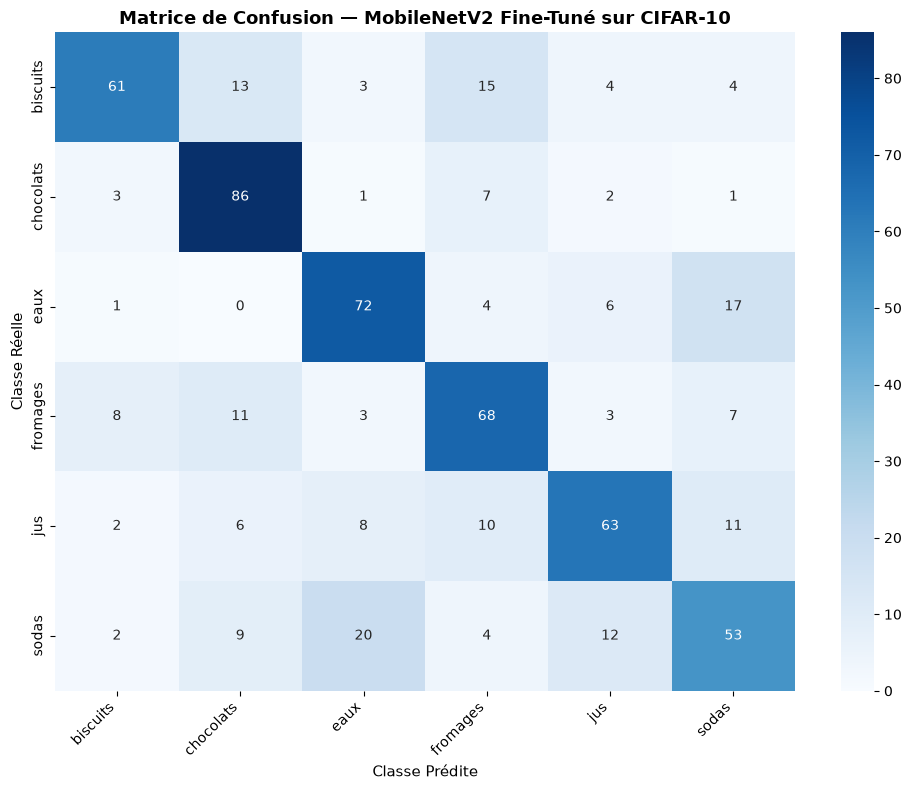

In [ ]:
cm = confusion_matrix(y_test_raw, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de Confusion — MobileNetV2 Fine-Tuné",
          fontsize=13, fontweight='bold')
plt.xlabel("Classe Prédite", fontsize=11)
plt.ylabel("Classe Réelle", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()